# PaySim : analyse exploratoire guidée

**Lot 4.0, étape 1.** Ce notebook lit le CSV PaySim brut depuis la racine du dépôt. Il ne modifie pas les données et n'entraîne aucun modèle. `isFraud` est consulté uniquement pour l'analyse hors ligne. Les autres labels ne sont pas des variables prédictives.

Les deux premières figures montrent le déséquilibre des classes et l'étendue des montants. Les conclusions sur les montants selon le label, les types, le temps et les soldes attendent la discussion avec l'utilisateur.


In [1]:
from pathlib import Path
from hashlib import sha256
from html import escape
import math
import polars as pl

CSV = Path("data/raw/PS_20174392719_1491204439457_log.csv")
FIGURES = Path("docs/figures")
EXPECTED_SHA256 = "16910f90577b0d981bf8ff289714510bb89bc71bff7d3f220f024e287e4eea6b"
if not CSV.is_file():
    raise FileNotFoundError(f"CSV absent : {CSV}. Voir README.md pour le téléchargement.")
with CSV.open("rb") as source:
    digest = sha256()
    for block in iter(lambda: source.read(1024 * 1024), b""):
        digest.update(block)
assert digest.hexdigest() == EXPECTED_SHA256, "Empreinte du CSV différente de l'audit"

frame = pl.scan_csv(CSV).select("amount", "isFraud")
summary = frame.select(
    pl.len().alias("total"),
    (pl.col("isFraud") == 0).sum().alias("normal"),
    (pl.col("isFraud") == 1).sum().alias("fraud"),
    (~pl.col("isFraud").is_in([0, 1])).sum().alias("other_label"),
    (pl.col("amount") == 0).sum().alias("zeros"),
    (pl.col("amount") < 0).sum().alias("negatives"),
    pl.col("amount").min().alias("minimum"),
    pl.col("amount").max().alias("maximum"),
    pl.col("amount").median().alias("median"),
    pl.col("amount").quantile(0.90).alias("p90"),
    pl.col("amount").quantile(0.99).alias("p99"),
).collect().row(0, named=True)
assert summary["total"] == 6_362_620
assert summary["normal"] + summary["fraud"] == summary["total"]
assert summary["other_label"] == 0 and summary["negatives"] == 0

# Tranches [10**e, 10**(e+1)) pour les montants strictement positifs.
bins = (
    frame.filter(pl.col("amount") > 0)
    .with_columns(pl.col("amount").log10().floor().cast(pl.Int32).alias("exponent"))
    .group_by("exponent").agg(pl.len().alias("count"))
    .sort("exponent").collect()
)
assert sum(bins["count"].to_list()) + summary["zeros"] == summary["total"]
assert bins["exponent"].to_list() == list(range(-2, 8))
print({key: summary[key] for key in ("total", "normal", "fraud", "zeros", "minimum", "maximum", "median", "p90", "p99")})
print(bins)


In [2]:
def svg_text(x, y, value, *, size=16, fill="#183047", anchor="start", weight="normal"):
    return (f'<text x="{x}" y="{y}" font-family="Arial, sans-serif" '
            f'font-size="{size}" fill="{fill}" text-anchor="{anchor}" '
            f'font-weight="{weight}">{escape(str(value))}</text>')


def show_svg(svg):
    try:
        from IPython.display import SVG, display
    except ModuleNotFoundError:
        return
    display(SVG(svg))


def save_svg(name, svg):
    FIGURES.mkdir(parents=True, exist_ok=True)
    path = FIGURES / name
    path.write_text(svg, encoding="utf-8")
    return svg


def format_int(value):
    return f"{value:,}".replace(",", " ")


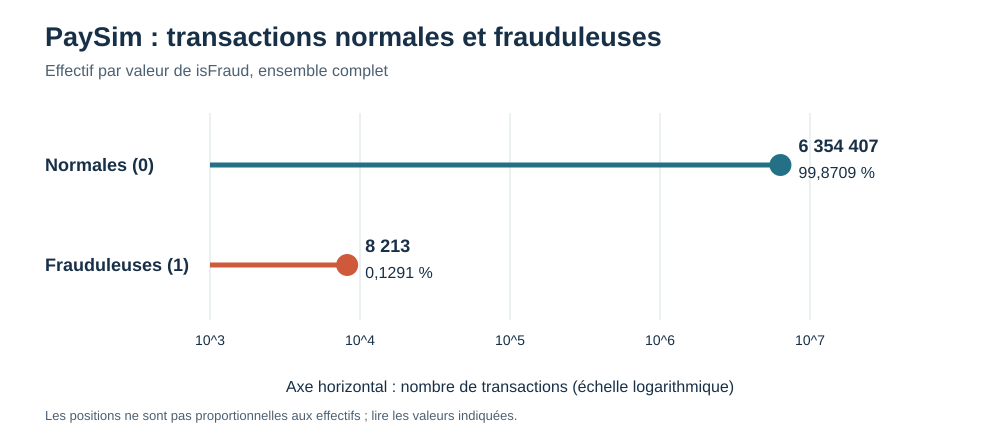

In [3]:
width, height = 1000, 440
left, right = 210, 810
x = lambda value: left + (math.log10(value) - 3) / 4 * (right - left)
parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
         '<rect width="100%" height="100%" fill="#ffffff"/>',
         svg_text(45, 46, "PaySim : transactions normales et frauduleuses", size=27, weight="bold"),
         svg_text(45, 76, "Effectif par valeur de isFraud, ensemble complet", size=16, fill="#4b6072")]
for power in range(3, 8):
    xpos = x(10 ** power)
    parts += [f'<line x1="{xpos}" y1="113" x2="{xpos}" y2="320" stroke="#d8e1e8"/>',
              svg_text(xpos, 345, f"10^{power}", size=14, anchor="middle")]
for y, name, value, color in [(165, "Normales (0)", summary["normal"], "#237087"),
                               (265, "Frauduleuses (1)", summary["fraud"], "#ce593b")]:
    xpos = x(value)
    parts += [svg_text(45, y + 6, name, size=18, weight="bold"),
              f'<line x1="{left}" y1="{y}" x2="{xpos}" y2="{y}" stroke="{color}" stroke-width="5"/>',
              f'<circle cx="{xpos}" cy="{y}" r="11" fill="{color}"/>',
              svg_text(min(xpos + 18, 845), y - 13, f"{format_int(value)}", size=18, weight="bold"),
              svg_text(min(xpos + 18, 845), y + 13, f"{value / summary['total'] * 100:.4f} %".replace(".", ","), size=16)]
parts += [svg_text(510, 392, "Axe horizontal : nombre de transactions (échelle logarithmique)", size=16, anchor="middle"),
          svg_text(45, 420, "Les positions ne sont pas proportionnelles aux effectifs ; lire les valeurs indiquées.", size=13, fill="#4b6072"),
          '</svg>']
class_svg = save_svg("eda_classes.svg", "\n".join(parts))
show_svg(class_svg)


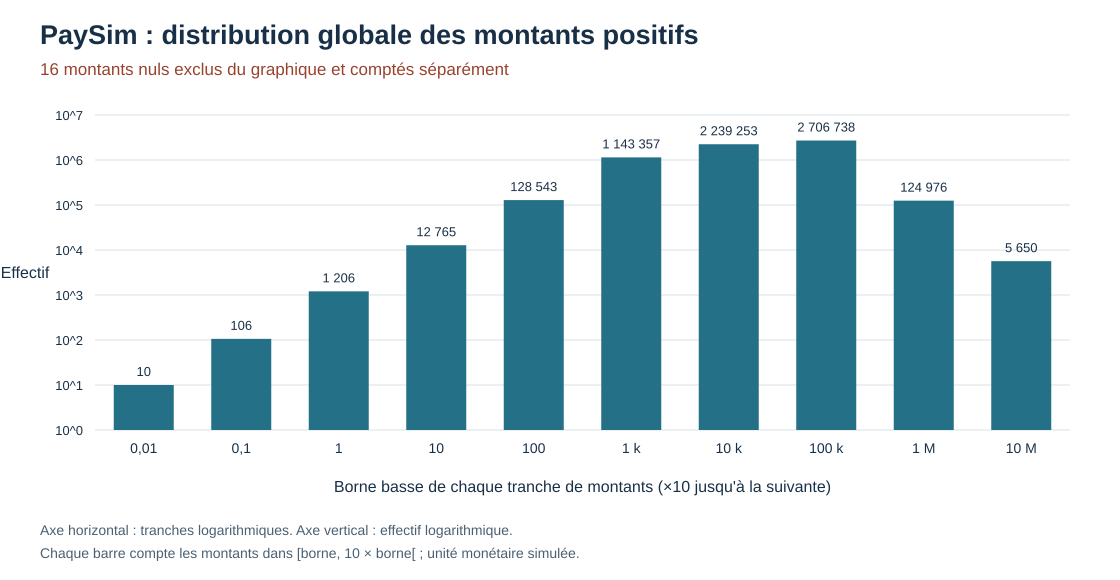

In [4]:
width, height = 1120, 580
left, right, top, bottom = 95, 1070, 115, 430
counts = bins["count"].to_list()
exponents = bins["exponent"].to_list()
max_power = 7
bar_width = (right - left) / len(counts)
y = lambda count: bottom - math.log10(count) / max_power * (bottom - top)
parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
         '<rect width="100%" height="100%" fill="#ffffff"/>',
         svg_text(40, 44, "PaySim : distribution globale des montants positifs", size=27, weight="bold"),
         svg_text(40, 75, f"{format_int(summary['zeros'])} montants nuls exclus du graphique et comptés séparément", size=17, fill="#9a422e")]
for power in range(0, max_power + 1):
    value = 10 ** power
    ypos = y(value)
    parts += [f'<line x1="{left}" y1="{ypos}" x2="{right}" y2="{ypos}" stroke="#d8e1e8"/>',
              svg_text(left - 12, ypos + 5, f"10^{power}", size=13, anchor="end")]
labels = ["0,01", "0,1", "1", "10", "100", "1 k", "10 k", "100 k", "1 M", "10 M"]
for i, (exp, count) in enumerate(zip(exponents, counts)):
    center = left + (i + 0.5) * bar_width
    ypos = y(count)
    parts += [f'<rect x="{center - 30}" y="{ypos}" width="60" height="{bottom - ypos}" fill="#237087"/>',
              svg_text(center, max(ypos - 9, 103), format_int(count), size=13, anchor="middle"),
              svg_text(center, 453, labels[i], size=14, anchor="middle")]
parts += [svg_text((left + right) / 2, 492, "Borne basse de chaque tranche de montants (×10 jusqu'à la suivante)", size=16, anchor="middle"),
          svg_text(25, 278, "Effectif", size=16, anchor="middle"),
          svg_text(40, 535, "Axe horizontal : tranches logarithmiques. Axe vertical : effectif logarithmique.", size=14, fill="#4b6072"),
          svg_text(40, 558, "Chaque barre compte les montants dans [borne, 10 × borne[ ; unité monétaire simulée.", size=14, fill="#4b6072"),
          '</svg>']
amount_svg = save_svg("eda_montants_globaux.svg", "\n".join(parts))
show_svg(amount_svg)


## Vérification de l’hypothèse sur `log(amount)`

Le premier graphique des montants utilisait aussi un axe vertical logarithmique. Celui-ci utilise des tranches régulières de `log10(amount)` et un axe vertical linéaire pour examiner la forme de la distribution.


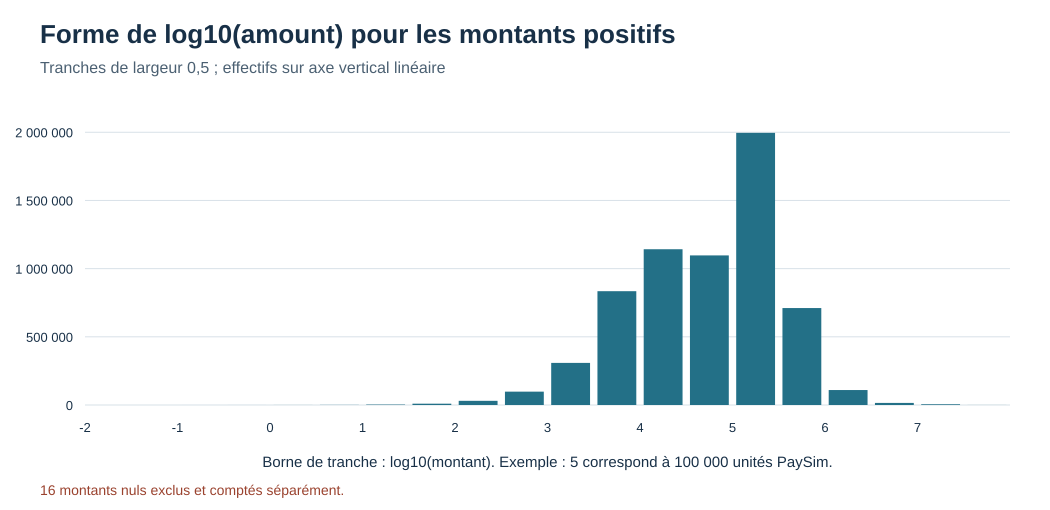

In [5]:
# Chaque tranche couvre 0,5 unité de log10(amount), soit un facteur 10**0,5.
log_bins = (
    frame.filter(pl.col("amount") > 0)
    .with_columns((pl.col("amount").log10() * 2).floor().cast(pl.Int32).alias("bin"))
    .group_by("bin").agg(pl.len().alias("count"))
    .sort("bin").collect()
)
assert sum(log_bins["count"].to_list()) == summary["total"] - summary["zeros"]
assert log_bins["bin"].to_list() == list(range(-4, 16))
log_stats = (
    frame.filter(pl.col("amount") > 0)
    .select(pl.col("amount").log10().mean().alias("mean"),
            pl.col("amount").log10().median().alias("median"),
            pl.col("amount").log10().skew().alias("skew"))
    .collect().row(0, named=True)
)
print("log10(amount), montants positifs :", log_stats)

width, height = 1050, 510
left, right, top, bottom = 85, 1010, 105, 405
counts = log_bins["count"].to_list()
bar_width = (right - left) / len(counts)
maximum = 2_200_000
parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
         '<rect width="100%" height="100%" fill="#ffffff"/>',
         svg_text(40, 43, "Forme de log10(amount) pour les montants positifs", size=26, weight="bold"),
         svg_text(40, 73, "Tranches de largeur 0,5 ; effectifs sur axe vertical linéaire", size=16, fill="#4b6072")]
for value in range(0, 2_000_001, 500_000):
    ypos = bottom - value / maximum * (bottom - top)
    parts += [f'<line x1="{left}" y1="{ypos}" x2="{right}" y2="{ypos}" stroke="#d8e1e8"/>',
              svg_text(left - 12, ypos + 5, format_int(value), size=13, anchor="end")]
for i, (bin_value, count) in enumerate(zip(log_bins["bin"].to_list(), counts)):
    center = left + (i + 0.5) * bar_width
    ypos = bottom - count / maximum * (bottom - top)
    parts.append(f'<rect x="{center - bar_width * 0.42}" y="{ypos}" width="{bar_width * 0.84}" height="{bottom - ypos}" fill="#237087"/>')
for log_value in range(-2, 9):
    i = 2 * (log_value + 2)
    if i < len(counts):
        xpos = left + i * bar_width
        parts.append(svg_text(xpos, 432, str(log_value), size=13, anchor="middle"))
parts += [svg_text((left + right) / 2, 467, "Borne de tranche : log10(montant). Exemple : 5 correspond à 100 000 unités PaySim.", size=15, anchor="middle"),
          svg_text(40, 495, "16 montants nuls exclus et comptés séparément.", size=14, fill="#9a422e"),
          '</svg>']
log_svg = save_svg("eda_log_montants.svg", "\n".join(parts))
show_svg(log_svg)


## Montants selon le label

Les tranches sont exactement celles de la vue précédente : largeur de 0,5 sur `log10(amount)`, plus les zéros séparés. Le premier graphique divise chaque effectif par le total de sa classe pour comparer les formes malgré le fort déséquilibre. Le second divise les fraudes de chaque tranche par toutes les transactions de cette même tranche pour obtenir son taux observé.


In [ ]:
# Tranches communes de largeur 0,5 sur log10(amount), plus une catégorie zéro.
class_bins = (
    frame.with_columns(
        pl.when(pl.col("amount") == 0).then(pl.lit(-999))
        .otherwise((pl.col("amount").log10() * 2).floor().cast(pl.Int32))
        .alias("bin")
    )
    .group_by("bin", "isFraud")
    .agg(pl.len().alias("count"))
    .sort("bin", "isFraud")
    .collect()
)
counts = {(bin_id, label): count for bin_id, label, count in class_bins.iter_rows()}
plot_bins = [-999, *range(-4, 16)]
rows = []
for bin_id in plot_bins:
    normal = counts.get((bin_id, 0), 0)
    fraud = counts.get((bin_id, 1), 0)
    total = normal + fraud
    rows.append({"bin": bin_id, "normal": normal, "fraud": fraud,
                 "total": total, "fraud_rate_pct": 100 * fraud / total if total else None,
                 "normal_class_pct": 100 * normal / summary["normal"],
                 "fraud_class_pct": 100 * fraud / summary["fraud"]})
assert sum(row["normal"] for row in rows) == summary["normal"]
assert sum(row["fraud"] for row in rows) == summary["fraud"]
assert sum(row["total"] for row in rows) == summary["total"]
assert abs(sum(row["normal_class_pct"] for row in rows) - 100) < 1e-9
assert abs(sum(row["fraud_class_pct"] for row in rows) - 100) < 1e-9
assert rows[0]["total"] == 16 and rows[0]["fraud"] == 16
assert [row["total"] for row in rows[1:]] == log_bins["count"].to_list()

def bin_label(bin_id):
    return "0" if bin_id == -999 else f"[{bin_id / 2:g}; {(bin_id + 1) / 2:g}["

print("log10(amount) : tranche [borne basse; borne haute[, sauf zéro")
print("tranche       total    fraudes  taux %")
for row in rows:
    print(f"{bin_label(row['bin']):>10}  {row['total']:>10}  {row['fraud']:>7}  {row['fraud_rate_pct']:>7.4f}")


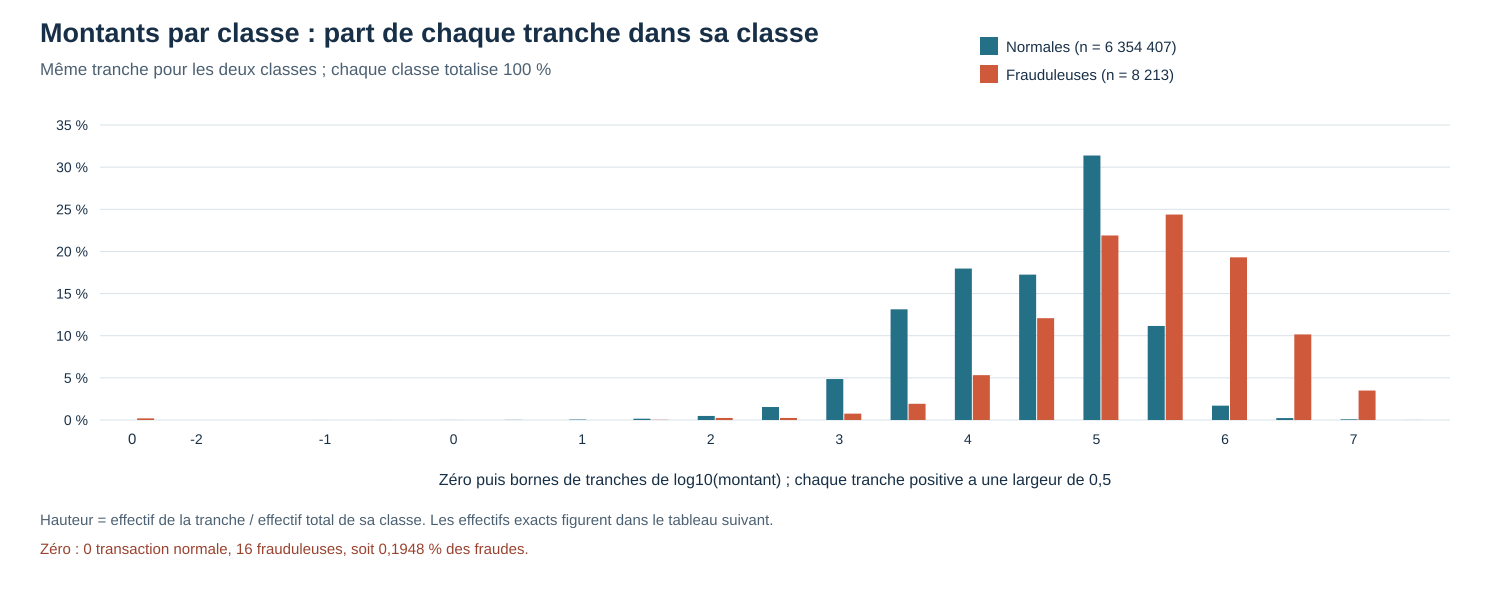

In [ ]:
width, height = 1500, 590
left, right, top, bottom = 100, 1450, 125, 420
bar_group = (right - left) / len(rows)
max_pct = 35
parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
         '<rect width="100%" height="100%" fill="#ffffff"/>',
         svg_text(40, 42, "Montants par classe : part de chaque tranche dans sa classe", size=27, weight="bold"),
         svg_text(40, 75, "Même tranche pour les deux classes ; chaque classe totalise 100 %", size=17, fill="#4b6072"),
         '<rect x="980" y="37" width="18" height="18" fill="#237087"/>',
         svg_text(1006, 52, f"Normales (n = {format_int(summary['normal'])})", size=15),
         '<rect x="980" y="65" width="18" height="18" fill="#ce593b"/>',
         svg_text(1006, 80, f"Frauduleuses (n = {format_int(summary['fraud'])})", size=15)]
for pct in range(0, max_pct + 1, 5):
    y = bottom - pct / max_pct * (bottom - top)
    parts += [f'<line x1="{left}" y1="{y}" x2="{right}" y2="{y}" stroke="#d8e1e8"/>',
              svg_text(left - 12, y + 5, f"{pct} %", size=14, anchor="end")]
for i, row in enumerate(rows):
    center = left + (i + .5) * bar_group
    for offset, value, color in [(-13, row["normal_class_pct"], "#237087"),
                                 (5, row["fraud_class_pct"], "#ce593b")]:
        y = bottom - value / max_pct * (bottom - top)
        parts.append(f'<rect x="{center + offset}" y="{y}" width="17" height="{bottom - y}" fill="{color}"/>')
    if i == 0:
        parts.append(svg_text(center, 444, "0", size=15, anchor="middle"))
    elif (row["bin"] + 4) % 2 == 0:
        parts.append(svg_text(center, 444, f"{row['bin'] / 2:g}", size=14, anchor="middle"))
parts += [svg_text((left + right) / 2, 485, "Zéro puis bornes de tranches de log10(montant) ; chaque tranche positive a une largeur de 0,5", size=16, anchor="middle"),
          svg_text(40, 525, "Hauteur = effectif de la tranche / effectif total de sa classe. Les effectifs exacts figurent dans le tableau suivant.", size=15, fill="#4b6072"),
          svg_text(40, 554, "Zéro : 0 transaction normale, 16 frauduleuses, soit 0,1948 % des fraudes.", size=15, fill="#9a422e"),
          '</svg>']
class_amount_svg = save_svg("eda_montants_par_classe.svg", "\n".join(parts))
show_svg(class_amount_svg)


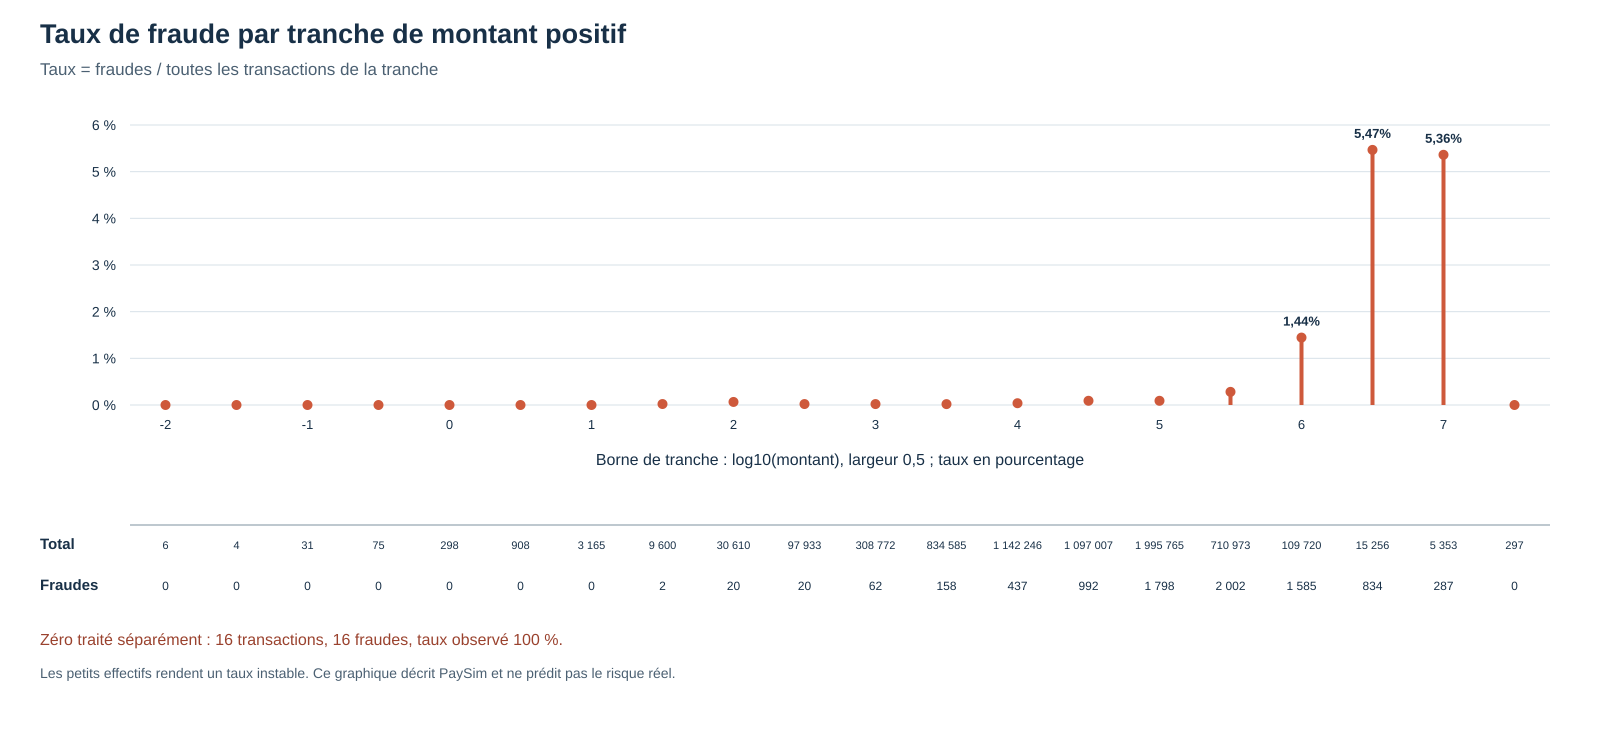

In [ ]:
width, height = 1600, 750
left, right, top, bottom = 130, 1550, 125, 405
positive = rows[1:]
slot = (right - left) / len(positive)
max_rate = 6.0
parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
         '<rect width="100%" height="100%" fill="#ffffff"/>',
         svg_text(40, 43, "Taux de fraude par tranche de montant positif", size=27, weight="bold"),
         svg_text(40, 75, "Taux = fraudes / toutes les transactions de la tranche", size=17, fill="#4b6072")]
for pct in range(0, 7):
    y = bottom - pct / max_rate * (bottom - top)
    parts += [f'<line x1="{left}" y1="{y}" x2="{right}" y2="{y}" stroke="#d8e1e8"/>',
              svg_text(left - 14, y + 5, f"{pct} %", size=14, anchor="end")]
for i, row in enumerate(positive):
    center = left + (i + .5) * slot
    y = bottom - row["fraud_rate_pct"] / max_rate * (bottom - top)
    parts += [f'<line x1="{center}" y1="{bottom}" x2="{center}" y2="{y}" stroke="#ce593b" stroke-width="4"/>',
              f'<circle cx="{center}" cy="{y}" r="5" fill="#ce593b"/>']
    if row["fraud_rate_pct"] >= 1:
        parts.append(svg_text(center, y - 12, f"{row['fraud_rate_pct']:.2f}%".replace(".", ","), size=13, anchor="middle", weight="bold"))
    if i % 2 == 0:
        parts.append(svg_text(center, 429, f"{row['bin'] / 2:g}", size=13, anchor="middle"))
parts += [svg_text((left + right) / 2, 465, "Borne de tranche : log10(montant), largeur 0,5 ; taux en pourcentage", size=16, anchor="middle"),
          f'<line x1="{left}" y1="525" x2="{right}" y2="525" stroke="#7d91a0"/>',
          svg_text(40, 549, "Total", size=15, weight="bold"),
          svg_text(40, 590, "Fraudes", size=15, weight="bold")]
for i, row in enumerate(positive):
    center = left + (i + .5) * slot
    parts += [svg_text(center, 549, format_int(row["total"]), size=11, anchor="middle"),
              svg_text(center, 590, format_int(row["fraud"]), size=12, anchor="middle")]
parts += [svg_text(40, 645, "Zéro traité séparément : 16 transactions, 16 fraudes, taux observé 100 %.", size=16, fill="#9a422e"),
          svg_text(40, 678, "Les petits effectifs rendent un taux instable. Ce graphique décrit PaySim et ne prédit pas le risque réel.", size=14, fill="#4b6072"),
          '</svg>']
rate_svg = save_svg("eda_taux_fraude_par_montant.svg", "\n".join(parts))
show_svg(rate_svg)


## Hypothèse 1 : rôle du type de transaction

Le type peut modifier la composition des tranches de montant. Nous conservons les mêmes bornes de montant, comptons toutes les combinaisons `type × tranche`, puis calculons le taux dans chaque combinaison. Les cinq tranches affichées couvrent 100 000 à environ 31,6 millions d'unités PaySim et répondent aux observations de l'utilisateur. Le calcul et les contrôles portent sur toutes les tranches, y compris zéro.


In [ ]:
# Même source et mêmes bornes que l'analyse des montants, avec le type en plus.
type_frame = pl.scan_csv(CSV).select("type", "amount", "isFraud")
type_bins = (
    type_frame.with_columns(
        pl.when(pl.col("amount") == 0).then(pl.lit(-999))
        .otherwise((pl.col("amount").log10() * 2).floor().cast(pl.Int32))
        .alias("bin")
    )
    .group_by("bin", "type")
    .agg(pl.len().alias("total"), pl.col("isFraud").sum().alias("fraud"))
    .sort("bin", "type").collect()
)
type_names = ["CASH_IN", "CASH_OUT", "DEBIT", "PAYMENT", "TRANSFER"]
type_counts = {(bin_id, kind): (total, fraud)
               for bin_id, kind, total, fraud in type_bins.iter_rows()}
type_totals = {kind: (
    sum(type_counts.get((bin_id, kind), (0, 0))[0] for bin_id in plot_bins),
    sum(type_counts.get((bin_id, kind), (0, 0))[1] for bin_id in plot_bins)
) for kind in type_names}
assert sum(n for n, _ in type_totals.values()) == summary["total"]
assert sum(k for _, k in type_totals.values()) == summary["fraud"]
for row in rows:
    assert sum(type_counts.get((row["bin"], kind), (0, 0))[0] for kind in type_names) == row["total"]
    assert sum(type_counts.get((row["bin"], kind), (0, 0))[1] for kind in type_names) == row["fraud"]
assert type_counts.get((-999, "CASH_OUT")) == (16, 16)
focus_bins = [10, 11, 12, 13, 14]
focus_labels = ["100 k–316 k", "316 k–1 M", "1 M–3,16 M", "3,16 M–10 M", "10 M–31,6 M"]
print("Type : transactions, fraudes, taux observé")
for kind in type_names:
    n, k = type_totals[kind]
    print(kind, n, k, f"{100*k/n:.4f} %")
print("Par type et tranche : log10 borne basse, type, transactions, fraudes, taux observé")
for bin_id in focus_bins:
    for kind in type_names:
        n, k = type_counts.get((bin_id, kind), (0, 0))
        if n:
            print(bin_id / 2, kind, n, k, f"{100*k/n:.4f} %")


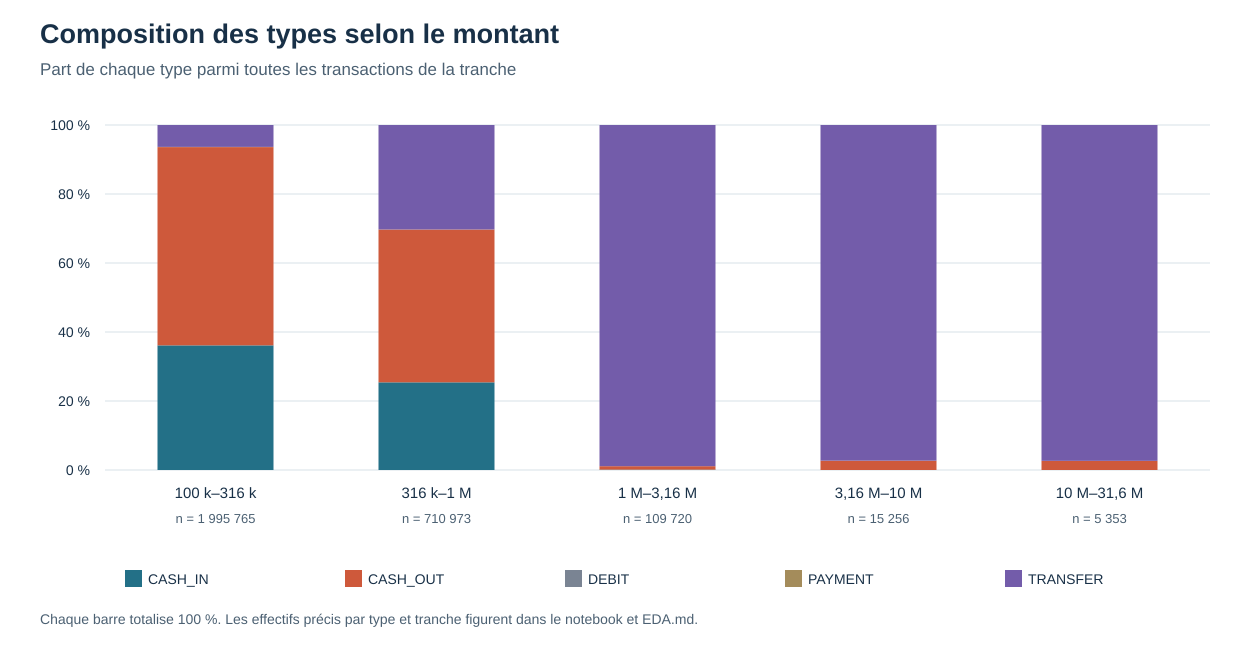

In [ ]:
width, height = 1260, 650
left, right, top, bottom = 105, 1210, 125, 470
colors = {"CASH_IN": "#237087", "CASH_OUT": "#ce593b", "DEBIT": "#7a8493",
          "PAYMENT": "#a48c5b", "TRANSFER": "#735caa"}
parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
         '<rect width="100%" height="100%" fill="#ffffff"/>',
         svg_text(40, 43, "Composition des types selon le montant", size=27, weight="bold"),
         svg_text(40, 75, "Part de chaque type parmi toutes les transactions de la tranche", size=17, fill="#4b6072")]
for pct in range(0, 101, 20):
    y = bottom - pct / 100 * (bottom - top)
    parts += [f'<line x1="{left}" y1="{y}" x2="{right}" y2="{y}" stroke="#d8e1e8"/>',
              svg_text(left - 15, y + 5, f"{pct} %", size=14, anchor="end")]
for i, bin_id in enumerate(focus_bins):
    center = left + (i + .5) * (right - left) / len(focus_bins)
    total = next(row["total"] for row in rows if row["bin"] == bin_id)
    y_bottom = bottom
    for kind in type_names:
        n, _ = type_counts.get((bin_id, kind), (0, 0))
        height_part = n / total * (bottom - top)
        y_bottom -= height_part
        parts.append(f'<rect x="{center-58}" y="{y_bottom}" width="116" height="{height_part}" fill="{colors[kind]}"/>')
    parts += [svg_text(center, 498, focus_labels[i], size=15, anchor="middle"),
              svg_text(center, 523, f"n = {format_int(total)}", size=13, anchor="middle", fill="#4b6072")]
legend_x = 125
for kind in type_names:
    parts += [f'<rect x="{legend_x}" y="570" width="17" height="17" fill="{colors[kind]}"/>',
              svg_text(legend_x + 23, 584, kind, size=14)]
    legend_x += 220
parts += [svg_text(40, 624, "Chaque barre totalise 100 %. Les effectifs précis par type et tranche figurent dans le notebook et EDA.md.", size=14, fill="#4b6072"),
          '</svg>']
composition_svg = save_svg("eda_composition_types_par_montant.svg", "\n".join(parts))
show_svg(composition_svg)


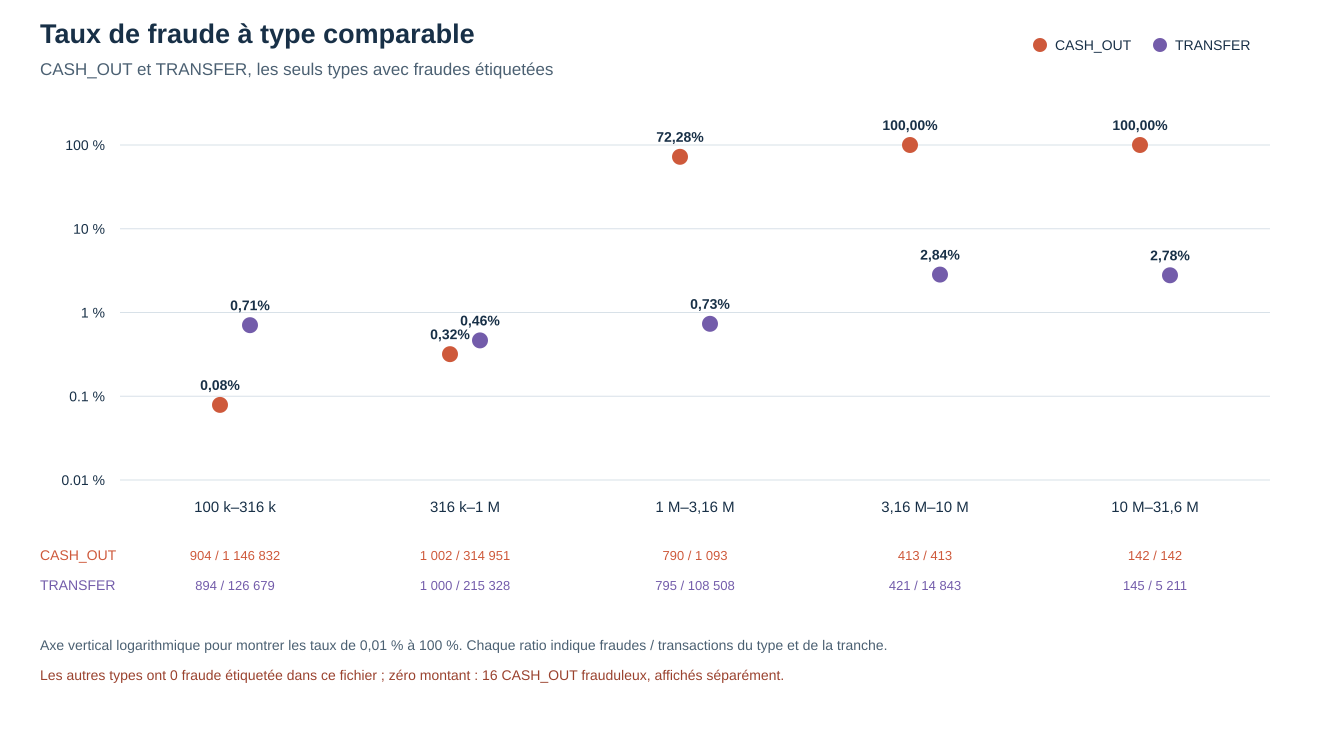

In [ ]:
width, height = 1320, 730
left, right, top, bottom = 120, 1270, 145, 480
colors = {"CASH_OUT": "#ce593b", "TRANSFER": "#735caa"}
log_min, log_max = -2.0, 2.0
ypos = lambda rate: bottom - (math.log10(rate) - log_min) / (log_max - log_min) * (bottom - top)
parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
         '<rect width="100%" height="100%" fill="#ffffff"/>',
         svg_text(40, 43, "Taux de fraude à type comparable", size=27, weight="bold"),
         svg_text(40, 75, "CASH_OUT et TRANSFER, les seuls types avec fraudes étiquetées", size=17, fill="#4b6072"),
         '<circle cx="1040" cy="45" r="7" fill="#ce593b"/>',
         svg_text(1055, 50, "CASH_OUT", size=14),
         '<circle cx="1160" cy="45" r="7" fill="#735caa"/>',
         svg_text(1175, 50, "TRANSFER", size=14)]
for rate_tick in [0.01, 0.1, 1, 10, 100]:
    y = ypos(rate_tick)
    parts += [f'<line x1="{left}" y1="{y}" x2="{right}" y2="{y}" stroke="#d8e1e8"/>',
              svg_text(left - 15, y + 5, f"{rate_tick:g} %", size=14, anchor="end")]
for i, bin_id in enumerate(focus_bins):
    center = left + (i + .5) * (right - left) / len(focus_bins)
    for dx, kind in [(-15, "CASH_OUT"), (15, "TRANSFER")]:
        n, k = type_counts[(bin_id, kind)]
        rate_value = 100 * k / n
        y = ypos(rate_value)
        parts += [f'<circle cx="{center+dx}" cy="{y}" r="8" fill="{colors[kind]}"/>',
                  svg_text(center + dx, y - 15, f"{rate_value:.2f}%".replace(".", ","), size=14, anchor="middle", weight="bold")]
    parts += [svg_text(center, 512, focus_labels[i], size=15, anchor="middle"),
              svg_text(center, 560, f"{format_int(type_counts[(bin_id, 'CASH_OUT')][1])} / {format_int(type_counts[(bin_id, 'CASH_OUT')][0])}", size=13, anchor="middle", fill=colors["CASH_OUT"]),
              svg_text(center, 590, f"{format_int(type_counts[(bin_id, 'TRANSFER')][1])} / {format_int(type_counts[(bin_id, 'TRANSFER')][0])}", size=13, anchor="middle", fill=colors["TRANSFER"])]
parts += [svg_text(40, 560, "CASH_OUT", size=14, fill=colors["CASH_OUT"]),
          svg_text(40, 590, "TRANSFER", size=14, fill=colors["TRANSFER"]),
          svg_text(40, 650, "Axe vertical logarithmique pour montrer les taux de 0,01 % à 100 %. Chaque ratio indique fraudes / transactions du type et de la tranche.", size=14, fill="#4b6072"),
          svg_text(40, 680, "Les autres types ont 0 fraude étiquetée dans ce fichier ; zéro montant : 16 CASH_OUT frauduleux, affichés séparément.", size=14, fill="#9a422e"),
          '</svg>']
type_rate_svg = save_svg("eda_taux_par_type_et_montant.svg", "\n".join(parts))
show_svg(type_rate_svg)


## Prochaine discussion

Nous confronterons l’hypothèse au résultat : la composition des types change, mais le taux change aussi à l’intérieur de certains types. Les effets du temps et des soldes attendent une étape distincte. Aucun modèle n’est entraîné.
